# Reproduce Experiment 01 from the public record

ThePickLog's first experiment pre-registered an exit rule on 2026-06-23 and published its verdict on 2026-07-29: **the rule lost to simply selling at the first day's close, −3.0 percentage points per trade, n = 309.**

This notebook rebuilds that number from scratch. It does not import any ThePickLog code. It:

1. downloads `picks.csv` and `outcomes.csv` **exactly as they stood on the verdict day** (git commit `402be29`),
2. checks their SHA-256 against the project's public, hash-chained `integrity_ledger.csv`, so you know the files weren't swapped,
3. applies the registered rule and recomputes the verdict, with pooled and ticker-clustered bootstrap intervals,
4. repeats the calculation on today's files, after every later correction.

Runs in a few seconds with pandas and numpy. Nothing here is investment advice.

Sources: [Experiment 01](https://thepicklog.com/experiment-01.html) · [HYPOTHESES.md](https://github.com/joshldavis/thepicklog/blob/main/HYPOTHESES.md) · [AUDIT_LOG.md](https://github.com/joshldavis/thepicklog/blob/main/AUDIT_LOG.md)

In [1]:
import hashlib, io, urllib.request
import numpy as np, pandas as pd

COMMIT = "402be29"   # "Gate-1 verdict: FAIL" — the commit that published the verdict, 2026-07-29
RAW = f"https://raw.githubusercontent.com/joshldavis/thepicklog/{COMMIT}/"

def fetch(url):
    with urllib.request.urlopen(url, timeout=60) as r:
        return r.read()

picks_bytes, outs_bytes = fetch(RAW + "picks.csv"), fetch(RAW + "outcomes.csv")
ledger = pd.read_csv(io.BytesIO(fetch("https://thepicklog.com/integrity_ledger.csv")), header=None)
sha = lambda b: hashlib.sha256(b).hexdigest()
print("picks.csv   ", sha(picks_bytes))
print("outcomes.csv", sha(outs_bytes))

picks.csv    68bd2897838e97550aff4fc0217237ae663fd7ba1cad103823c4e0e031f91117
outcomes.csv 2831b3321a165443ba34f91db76e979d94a20535eaddb82de2a0968509f78d76


## 1. Verify the files against the public ledger

Every scan and grade appends a row to `integrity_ledger.csv` with the SHA-256 of each log file plus a running chain hash. If the two hashes above appear together in a ledger row, these are the files the project sealed that day.

In [2]:
match = ledger[(ledger[2] == sha(picks_bytes)) & (ledger[3] == sha(outs_bytes))]
print(match[[0, 1]].to_string(header=["sealed at (UTC)", "event"], index=False))
assert len(match), "hashes not found in the public ledger"
print("\nVerified: these are the sealed verdict-day files.")

                 sealed at (UTC) event
2026-07-29T21:56:26.514825+00:00 grade

Verified: these are the sealed verdict-day files.


## 2. The registered rule

From `HYPOTHESES.md` (H-EX1, registered 2026-06-23):

- **Cohort:** the v0.2 screen. **Window:** picks with `trading_date` after 2026-06-23.
- **Rule:** buy at the open, rest a +10% limit for five days. If the five-day high reaches +10% (`mfe_5d ≥ 10`), book **+8% net** (target minus a 2% cost haircut). Otherwise exit at the fifth day's close (`ret_open_5dclose_net`).
- **Baseline it must beat:** sell at the first day's close (`ret_open_close_net`).
- **Statistic:** mean of the paired per-pick difference, rule minus baseline.

In [3]:
def load(p_bytes, o_bytes):
    p = pd.read_csv(io.BytesIO(p_bytes), dtype=str)
    o = pd.read_csv(io.BytesIO(o_bytes), dtype=str)
    m = o.merge(p[["pick_id", "published_at", "model_version"]], on="pick_id")
    for c in ["ret_open_close_net", "ret_open_5dclose_net", "mfe_5d"]:
        m[c] = pd.to_numeric(m[c], errors="coerce")
    return m

def h_ex1(m, drop_late=False):
    d = m[m.model_version.fillna("").str.startswith("v0.2") & (m.trading_date > "2026-06-23")].copy()
    if drop_late:   # the 2026-08-04 correction: drop picks logged at or after their own session's open
        pub = pd.to_datetime(d.published_at, utc=True).dt.tz_convert("America/New_York")
        opened = pd.to_datetime(d.trading_date + " 09:30").dt.tz_localize("America/New_York")
        d = d[pub < opened]
    d = d.dropna(subset=["ret_open_close_net", "ret_open_5dclose_net", "mfe_5d"])
    d["rule"] = np.where(d.mfe_5d >= 10, 8.0, d.ret_open_5dclose_net)
    d["baseline"] = d.ret_open_close_net
    d["diff"] = d.rule - d.baseline
    return d

def pooled_ci(x, B=4000, seed=7):
    r = np.random.default_rng(seed); x = np.asarray(x)
    return np.percentile(x[r.integers(0, len(x), (B, len(x)))].mean(1), [2.5, 97.5])

def cluster_ci(d, B=4000, seed=7):
    # resample whole tickers: repeated picks of the same 16 names are not independent
    r = np.random.default_rng(seed); g = [v["diff"].values for _, v in d.groupby("ticker")]
    return np.percentile([np.concatenate([g[i] for i in r.integers(0, len(g), len(g))]).mean()
                          for _ in range(B)], [2.5, 97.5])

def verdict(d, label):
    favor = int((d.groupby("ticker")["diff"].mean() > 0).sum())
    lo, hi = pooled_ci(d["diff"]); clo, chi = cluster_ci(d)
    return {"": label, "n": len(d), "rule mean %": round(d.rule.mean(), 1),
            "baseline mean %": round(d.baseline.mean(), 1), "Δ pp": round(d["diff"].mean(), 1),
            "95% CI": f"[{lo:.1f}, {hi:.1f}]", "ticker-clustered CI": f"[{clo:.1f}, {chi:.1f}]",
            "tickers": d.ticker.nunique(), "tickers favoring rule": favor}

m0729 = load(picks_bytes, outs_bytes)
d = h_ex1(m0729)
pd.DataFrame([verdict(d, "Recomputed from 07-29 files"),
              {"": "Published 2026-07-29", "n": 309, "rule mean %": -5.9, "baseline mean %": -2.9, "Δ pp": -3.0,
               "95% CI": "[-4.4, -1.5]", "ticker-clustered CI": "[-6.0, -0.6]", "tickers": 16, "tickers favoring rule": 5}]
            ).set_index("")

,n,rule mean %,baseline mean %,Δ pp,95% CI,ticker-clustered CI,tickers,tickers favoring rule
,,,,,,,,
Recomputed from 07-29 files,309,-5.9,-2.9,-3.0,"[-4.4, -1.6]","[-5.9, -0.6]",16,5
Published 2026-07-29,309,-5.9,-2.9,-3.0,"[-4.4, -1.5]","[-6.0, -0.6]",16,5


The point estimate, n, the means and the ticker counts match exactly. The interval endpoints can differ by about 0.1 because this notebook's bootstrap uses numpy's generator rather than the project's standard-library one; both use 4,000 resamples.

## 3. The sign flipped as the sample grew

The verdict page reports the edge at 30, 200 and 309 trades. Ordering picks by trading date, here is the running estimate.

 trades graded  Δ pp so far
            30          1.7
           200         -2.1
           309         -3.0


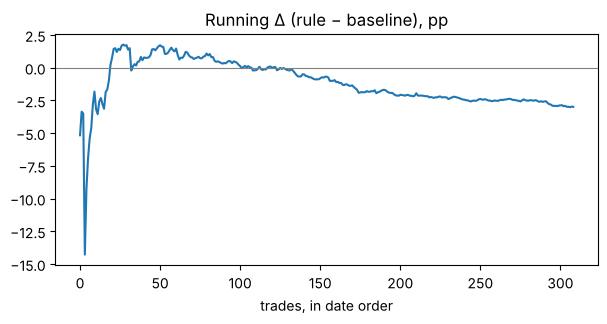

In [4]:
ds = d.sort_values(["trading_date", "pick_id"]).reset_index(drop=True)
running = ds["diff"].expanding().mean()
print(pd.DataFrame({"trades graded": [30, 200, len(ds)],
                    "Δ pp so far": [round(running[n - 1], 1) for n in (30, 200, len(ds))]}).to_string(index=False))
try:
    import matplotlib.pyplot as plt
    ax = running.plot(figsize=(7, 3), title="Running Δ (rule − baseline), pp")
    ax.axhline(0, color="grey", lw=0.8); ax.set_xlabel("trades, in date order"); plt.show()
except ImportError:
    pass

These match the published +1.7, −2.1 and −3.0. At 30 trades the rule looked like it worked; the sign inverted and then held as the sample grew.

## 4. Does deleting the single best trade change anything?

The cheapest check you can run on any backtest.

In [5]:
best = d.loc[d["diff"].idxmax()]
print(f"best single trade: {best.ticker} {best.trading_date}, Δ {best['diff']:+.1f} pp")
print(f"Δ with it {d['diff'].mean():+.2f} pp, without it {d.drop(best.name)['diff'].mean():+.2f} pp")

best single trade: VMAR 2026-07-14, Δ +37.1 pp
Δ with it -2.99 pp, without it -3.12 pp


## 5. After every later correction

Two corrections came after the verdict: 128 picks logged after the opening bell were excluded (2026-08-04), and some five-day grades were re-computed (2026-10-07, 2026-10-25). Today's files carry all of them. Same 309 picks, then the same picks without the late-logged ones.

In [6]:
now = load(fetch("https://thepicklog.com/picks.csv"), fetch("https://thepicklog.com/outcomes.csv"))
ids = set(d.pick_id)
a = h_ex1(now); a = a[a.pick_id.isin(ids)]
b = h_ex1(now, drop_late=True); b = b[b.pick_id.isin(ids)]
pd.DataFrame([verdict(a, "Today's files, same picks"),
              verdict(b, "Today's files, late-logged picks excluded")]).set_index("")

,n,rule mean %,baseline mean %,Δ pp,95% CI,ticker-clustered CI,tickers,tickers favoring rule
,,,,,,,,
"Today's files, same picks",309,-5.9,-2.9,-3.0,"[-4.4, -1.6]","[-5.9, -0.6]",16,5
"Today's files, late-logged picks excluded",245,-5.6,-3.0,-2.6,"[-4.2, -1.0]","[-5.3, -0.3]",16,6


The later corrections leave these 309 rows unchanged. Excluding the late-logged picks shrinks the loss slightly, and its interval still excludes zero. **The verdict holds: the pre-registered exit rule loses to the simple same-day close.**

If you get a different number, open an issue on the [repository](https://github.com/joshldavis/thepicklog) or use the form on the [About page](https://thepicklog.com/about.html). The last significant correction to this record came from a reader.